# 1. Unitary dynamics

gbcs solves the dynamics of $N$ qubits coupled to $n$ bosonic modes when the coupling is an operator-valued Gaussian interaction,

$$\frac{\hat H}{\hbar\omega} = \sum_j \left(\tfrac12\hat r^{\mathsf T} H_j\,\hat r - r_j^{\mathsf T}\hat r + \tfrac12 H^0_j\right)\otimes|j\rangle\langle j| ,\qquad H_j = H_m + \sum_i J_i H_{q,i},\quad r_j = r_m + \sum_i J_i\, r_{q,i},$$

where $\hat r = (\hat x_1, \hat p_1, \dots, \hat x_n, \hat p_n)^{\mathsf T}$ and $J_i = \pm1$ is the label of qubit $i$ in the branch $j$. Time is $\tau = \omega t$.

Under such a Hamiltonian, a Gaussian mode times any qubit state evolves into a Gaussian-branched cat state (GBCS). Every element $\varrho_{jk} = \langle j|\hat\varrho|k\rangle$ of the joint state stays a Gaussian, with characteristic function

$$\chi_{jk}(\xi) = \varrho^q_{jk}(0)\,\exp\!\left(-\tfrac14\xi^{\mathsf T}\sigma_{jk}\,\xi + i\,\xi^{\mathsf T}\bar r_{jk} - \mathcal C_{jk} + i\phi_{jk}\right).$$

The library follows $\sigma_{jk}$, $\bar r_{jk}$, the contrast $\mathcal C_{jk}$ and the phase $\phi_{jk}$ in time. The qubit state is $\varrho^q_{jk}(\tau) = e^{-\mathcal C_{jk} + i\phi_{jk}}\varrho^q_{jk}(0)$. The vacuum has $\sigma = \mathbb 1$.

Paper: [arXiv:2510.01156](https://arxiv.org/abs/2510.01156).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gbcs import Quantum_State, Hamiltonian, QIT_Functions
from gbcs import Wigner_Functions

I2 = np.eye(2)

def show_wigner(ax, W, x, p, title):
    limit = np.max(np.abs(W))
    ax.imshow(W, origin='lower', extent=[x[0], x[-1], p[0], p[-1]], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xlabel('$x$')
    ax.set_title(title)

## The three objects

A `Hamiltonian` takes `H_array = [H_m, H_q1, ..., H_qN]`, `r_array = [r_m, r_q1, ..., r_qN]` and the qubit energies `H_q_0_array`. It recognises three cases from what is given:

- `'Gaussian'`: no coupling to the qubits;
- `'Force'`: linear coupling only, solved with the integral forms of Table II;
- `'General'`: quadratic coupling, solved branch by branch.

A `Quantum_State` holds the initial state, and its dynamics methods fill the time series: `sigma_JK_t` (T, 2^N, 2^N, 2n, 2n), `r_JK_t` (T, 2^N, 2^N, 2n, 1), `C_JK_t`, `phi_JK_t` and `rho_q_t` (T, 2^N, 2^N).

The branch index $j$ is read in binary, with bit 1 meaning label $+1$. For one qubit, index 0 is $-1$ and index 1 is $+1$; for two qubits:

In [2]:
for j in range(4):
    print(j, QIT_Functions.Extract_Qubit_Labels_Array(2, j))

0 [-1. -1.]
1 [-1.  1.]
2 [ 1. -1.]
3 [1. 1.]


## A mode on its own

A displaced squeezed state in a harmonic trap, $H_m = \mathbb 1$, rotates in phase space and its squeezing turns with it. Without qubits the state is a plain Gaussian, and the results are in `r_t` and `sigma_t`.

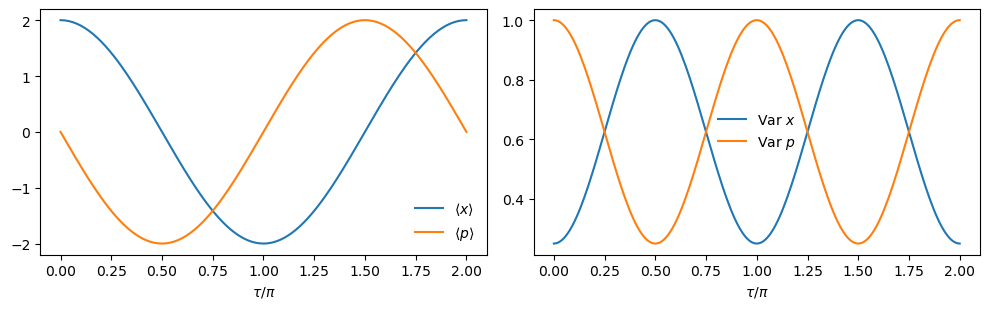

In [3]:
H = Hamiltonian(1, 1)
H.Initialize_Constant_Hamiltonians([I2], [np.zeros((2, 1))], np.array([0.0]))

G = Quantum_State(1, 1)
G.Initialize_Gaussian_State(np.array([[2.0], [0.0]]), np.diag([0.5, 2.0]), np.ones((1, 1)))
tau = np.linspace(0, 2*np.pi, 201)
G.Unitary_Dynamics_Numerical(H, tau)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(tau/np.pi, G.r_t[:, 0, 0], label=r'$\langle x\rangle$')
axes[0].plot(tau/np.pi, G.r_t[:, 1, 0], label=r'$\langle p\rangle$')
axes[1].plot(tau/np.pi, G.sigma_t[:, 0, 0]/2, label=r'Var $x$')
axes[1].plot(tau/np.pi, G.sigma_t[:, 1, 1]/2, label=r'Var $p$')
for ax in axes:
    ax.set_xlabel(r'$\tau/\pi$')
    ax.legend(frameon=False)
plt.tight_layout()

## Linear coupling: a Stern–Gerlach interferometer

A qubit pushes a trapped particle with the force $f_q\hat\sigma_z$, on top of a force $f_u$ it does not control: $H_m = \mathbb 1$, $r_m = (f_u, 0)$, $r_q = (f_q, 0)$. The two branches circle in phase space around $f_u \pm f_q$ and meet again at $\tau = 2\pi$. In between, the qubit coherence $e^{-\mathcal C}$ is lost to the which-path information and then comes back. The phase picked up is $\phi = 2 f_q f_u(\tau - \sin\tau)$, the signal of the unknown force.

In [4]:
f_q, f_u = 1.5, 0.5
H_sg = Hamiltonian(1, 1)
H_sg.Initialize_Constant_Hamiltonians([I2], [np.array([[f_u], [0.]]), np.array([[f_q], [0.]])], np.array([0.0]))
print(H_sg.type)

sg = Quantum_State(1, 1)
sg.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
sg.Unitary_Dynamics_Numerical(H_sg, tau)

['Constant', 'Force']


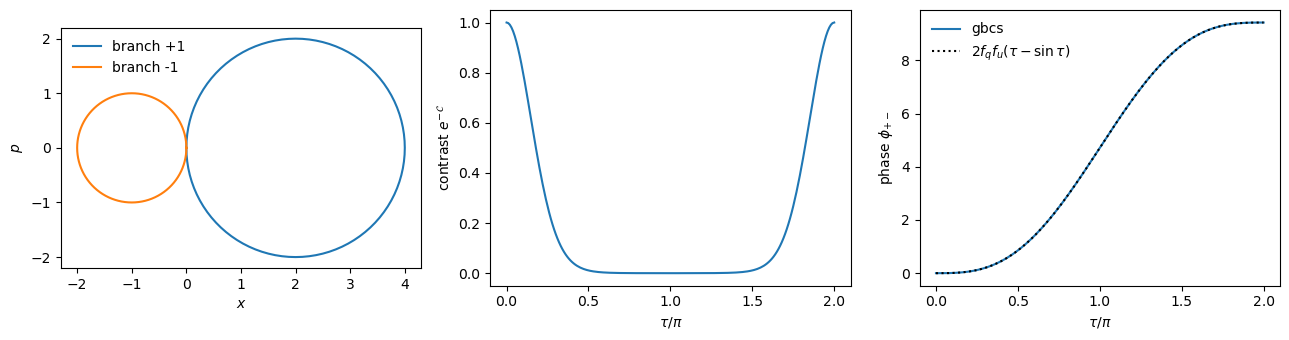

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for j, label in ((1, '+1'), (0, '-1')):
    axes[0].plot(sg.r_JK_t[:, j, j, 0, 0].real, sg.r_JK_t[:, j, j, 1, 0].real, label=f'branch {label}')
axes[0].set_aspect('equal')
axes[0].set_xlabel('$x$')
axes[0].set_ylabel('$p$')
axes[0].legend(frameon=False)

axes[1].plot(tau/np.pi, np.exp(-sg.C_JK_t[:, 1, 0]))
axes[1].set_ylabel(r'contrast $e^{-\mathcal{C}}$')

axes[2].plot(tau/np.pi, sg.phi_JK_t[:, 1, 0], label='gbcs')
axes[2].plot(tau/np.pi, 2*f_q*f_u*(tau - np.sin(tau)), 'k:', label=r'$2 f_q f_u(\tau - \sin\tau)$')
axes[2].set_ylabel(r'phase $\phi_{+-}$')
axes[2].legend(frameon=False)
for ax in axes[1:]:
    ax.set_xlabel(r'$\tau/\pi$')
plt.tight_layout()

## Quadratic coupling: conditional rotation of a squeezed state

With $H_j = (1 + j\mu)\mathbb 1$ the qubit changes the trap frequency, so each branch rotates at its own speed. The off-diagonal covariance $\sigma_{+-}$ becomes complex: it obeys a Riccati equation (Table I).

`solver='linear'` solves it with the linear map of the doubling method, and is the recommended solver for constant Hamiltonians. `solver='ode'` integrates the nested ODEs of Table I instead. Both give the same answer here.

In [6]:
mu = 0.25
H_rot = Hamiltonian(1, 1)
H_rot.Initialize_Constant_Hamiltonians([I2, mu*I2], [np.zeros((2, 1)), np.zeros((2, 1))], np.array([0.0]))
print(H_rot.type)

tau_rot = np.linspace(0, 4*np.pi, 201)
runs = {}
for solver in ('linear', 'ode'):
    G = Quantum_State(1, 1)
    G.Initialize_Gaussian_State(np.array([[2.5], [0.]]), np.diag([0.4, 2.5]), np.ones((2, 2))/2)
    G.Unitary_Dynamics_Numerical(H_rot, tau_rot, solver=solver)
    runs[solver] = G

rot = runs['linear']
print('largest difference in sigma:', np.max(np.abs(rot.sigma_JK_t - runs['ode'].sigma_JK_t)))
print('sigma_+- at tau = pi:\n', rot.sigma_JK_t[50, 1, 0].round(3))

['Constant', 'General']
largest difference in sigma: 2.968123957131916e-10
sigma_+- at tau = pi:
 [[ 0.69+0.724j -0.  +0.j   ]
 [-0.  +0.j     0.69-0.724j]]


At $\tau = \pi$ the two branches are a quarter turn apart. The Wigner function of the mode is the mixture of the two squeezed states, $\mathcal W_c$, plus the interference term $\mathcal W_q = 2\,\mathrm{Re}\,\mathcal W_{+-}$. Because $\sigma_{+-}$ is complex, the fringes are curved. $\mathcal W_q$ is not part of the reduced state of the mode, but a measurement of the qubit in the $\sigma_x$ basis reveals it (tutorial 3).

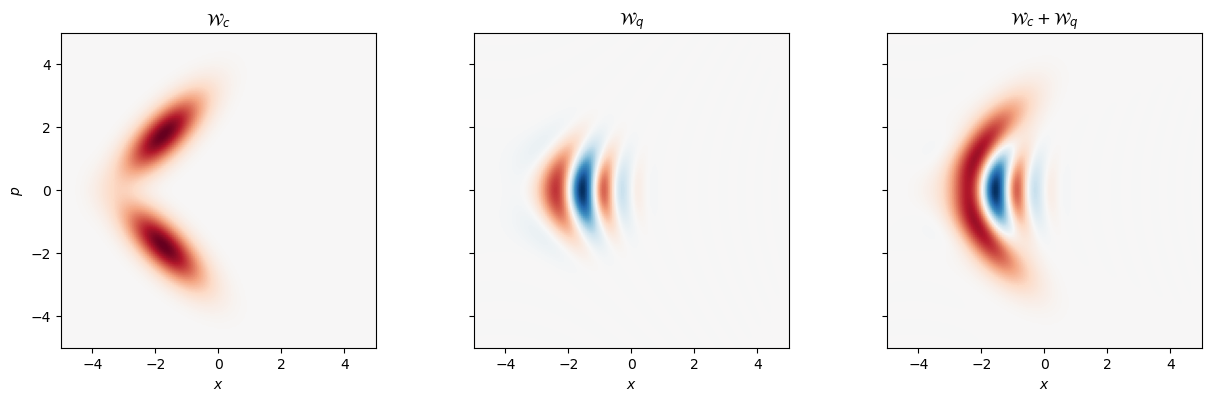

In [7]:
grid, x, p, _, _ = Wigner_Functions.Create_r_tilde_array(rot, 1.0, 0, 151)
W_c = Wigner_Functions.Wigner_Sum_Diagonal(rot, 50, grid)
W_q = Wigner_Functions.Wigner_Off_Diagonal(rot, 50, grid)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
show_wigner(axes[0], W_c, x, p, r'$\mathcal{W}_c$')
show_wigner(axes[1], W_q, x, p, r'$\mathcal{W}_q$')
show_wigner(axes[2], W_c + W_q, x, p, r'$\mathcal{W}_c + \mathcal{W}_q$')
axes[0].set_ylabel('$p$')
plt.tight_layout()

The contrast falls while the branches separate and recovers when the relative rotation $2\mu\tau$ completes a turn, at $\tau = \pi/\mu$.

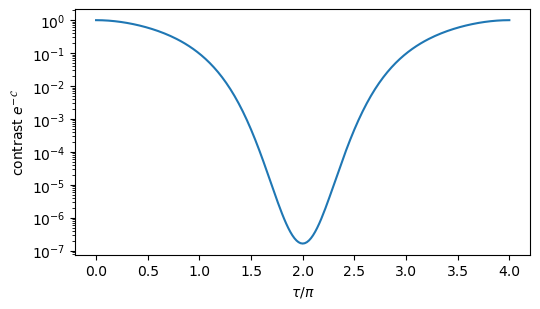

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.semilogy(tau_rot/np.pi, np.exp(-rot.C_JK_t[:, 1, 0].real))
ax.set_xlabel(r'$\tau/\pi$')
ax.set_ylabel(r'contrast $e^{-\mathcal{C}}$')
plt.tight_layout()

More qubits and modes work the same way: `Hamiltonian(N_qubits, n_modes)` with `N_qubits + 1` entries in `H_array` and `r_array`, each a $2n\times2n$ matrix or a $2n\times1$ vector. Noise is in tutorial 2, measurements in tutorial 3, and terms that act on the qubits alone (decay, drives) in tutorial 4.